# 05.08 DECISION TREES & RANDOM FORESTS - EXERCISES (SOLUTION)

This notebook contains practical exercises on decision trees and random forests exercises.

## Exercise 1: Decision Tree Classifier on the Iris Dataset

Load the Iris dataset and split in a train and test set (80/20). Train a `DecisionTreeClassifier` on the train set. Visualize the tree using `plot_tree()`.

**Scaling note:** Decision trees are **not sensitive to feature scaling**, so standardization or normalization
is **not necessary** here.

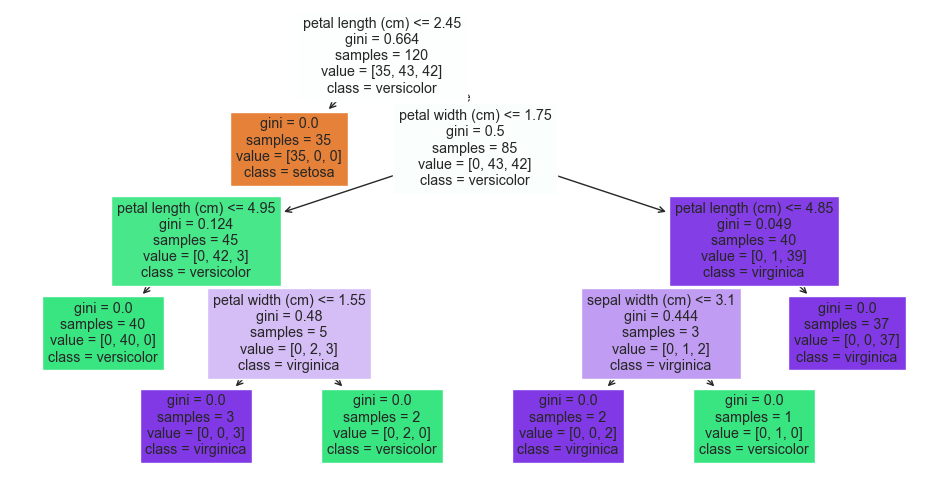

In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)

plt.figure(figsize=(12,6))
plot_tree(clf, filled=True, feature_names=load_iris().feature_names, class_names=load_iris().target_names)
plt.show()


## Exercise 2: Experiment with Tree Depth

Try out hyperparameter `max_depth` for the values [1, 3, 5, None] and observe underfitting vs. overfitting by comparing the accuracy on the train set with the accuracy on the test set.

In [31]:
from sklearn.metrics import accuracy_score

depths = [1, 3, 5, None]
for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=42)
    clf.fit(X_train, y_train)
    y_pred_train = clf.predict(X_train)
    y_pred_test = clf.predict(X_test)
    print(f"Depth={d}, Accuracy on Train={accuracy_score(y_train, y_pred_train):.3f}, Accuracy on Test={accuracy_score(y_test, y_pred_test):.3f}")


Depth=1, Accuracy on Train=0.667, Accuracy on Test=0.667
Depth=3, Accuracy on Train=0.958, Accuracy on Test=1.000
Depth=5, Accuracy on Train=1.000, Accuracy on Test=0.967
Depth=None, Accuracy on Train=1.000, Accuracy on Test=0.967


## Exercise 3: Confusion Matrix and Classification Report

Split the complete dataset into a train and test set (70/30). Train a Decision Tree Classifier with max_depth=2. Generate and interpret the confusion matrix, precision, recall, and F1 scores for the test set.

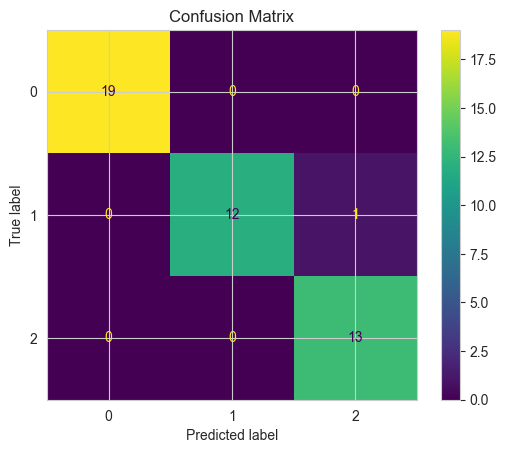


Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      0.92      0.96        13
           2       0.93      1.00      0.96        13

    accuracy                           0.98        45
   macro avg       0.98      0.97      0.97        45
weighted avg       0.98      0.98      0.98        45



In [32]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, ConfusionMatrixDisplay

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

clf = DecisionTreeClassifier(random_state=42, max_depth=2)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title('Confusion Matrix')
plt.show()
print("\nClassification Report:\n", classification_report(y_test, y_pred))


## Exercise 4: Random Forest Classifier

Train a `RandomForestClassifier` with  100 estimators and max_depth=2 and provide a classification report for the test set.


In [33]:

# Exercise 4: Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=2)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

